# 20 · Modelo de sostenibilidad de la opción C (relevo por horas)
**UCA Analítica para los Negocios · Observatorio del Cuidado · 15 oct 2026 · pendiente de doble revisión**

**Para qué decisión existe este notebook.** El 5 oct 2026 el equipo eligió la opción C: relevo acotado por horas para la persona cuidadora familiar de alta intensidad. El estudio de negocio v0.2 calculó el subsidio para 20 y 40 h/semana, que es otro producto. Este notebook rehace la economía unitaria para el relevo de 3 a 12 h/semana y responde cuatro preguntas:

1. ¿Cuánto cuesta una hora de relevo con carga laboral?
2. ¿Cuánto de ese costo cubre el hogar bajo la convención del 20 % del ingreso y cuánto queda por financiar?
3. ¿Cuánto financiamiento externo requiere el programa según la aceptación y el costo de operación?
4. ¿Qué efecto tendría que lograr el relevo para que un pagador por costo evitado (escenario C) lo financie?

**Qué SÍ permite afirmar.** Costos laborales directos al piso legal; copago y subsidio laboral por hogar bajo un umbral declarado; umbrales de equilibrio expresados como función de parámetros; qué supuesto mueve más el resultado.

**Qué NO permite afirmar.** Un punto de equilibrio único (la operación y la aceptación son POR DETERMINAR); disposición a pagar; cifras medidas de la CDMX (el dimensionamiento es una inferencia con tasas nacionales); que el relevo reduzca el daño o la salida del empleo (eso lo mide el piloto).

**Entradas.** CSV de `resultados/` (03, 04, 05, 06, 07, 14, 16 y 19). Lo único escrito aquí son supuestos declarados y marcados como tales.
**Salidas.** Figuras `figuras/f21` a `f25`. El libro de Excel con fórmulas vivas (`resultados/20_modelo_sostenibilidad.xlsx`) lo genera `20_modelo_sostenibilidad.py`; la sección 8 verifica que ambos coincidan.

In [1]:
import re, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

AQUI = Path.cwd()
if not (AQUI / 'resultados').exists():
    AQUI = AQUI / 'Analysis'          # por si se corre desde la raíz del repo
sys.path.insert(0, str(AQUI))
import estilo_graficas as eg
eg.estilo()
RES, FIG = AQUI / 'resultados', AQUI / 'figuras'
pd.options.display.float_format = '{:,.2f}'.format
def rd(n): return pd.read_csv(RES / n, encoding='utf-8-sig')

## 1. Entradas desde los resultados del proyecto
Ninguna cifra de esta sección se escribe a mano: se leen de los CSV. Si falta una fila esperada, el notebook se detiene.

In [2]:
r19 = rd('19_costo_hora_por_jornada.csv')
SAL = float(r19.salario_diario_2026.iloc[0])
DIV = {j: float(r19[r19.jornada == j].horas_max_jornada.iloc[0]) for j in ['Diurna', 'Mixta', 'Nocturna']}

r04 = rd('04_resumen.csv')
def v04(prefijo): return float(r04[r04.indicador.str.startswith(prefijo)].valor.iloc[0])
INPC = v04('Factor INPC')
EN_P25, EN_MED, EN_P75 = v04('Ingreso mensual p25 ponderado'), v04('Ingreso mensual mediano ponderado'), v04('Ingreso mensual p75 ponderado')

r14 = rd('14_enigh_resumen.csv')
def f14(prefijo, dominio):
    f = r14[(r14.indicador.str.startswith(prefijo)) & (r14.dominio == dominio)]
    assert len(f) == 1, (prefijo, dominio, len(f))
    return f.iloc[0]
DEFL = float(r14[r14.indicador.str.startswith('Deflactor')].valor.iloc[0])
IG_P25 = float(f14('Ingreso monetario mensual del hogar, p25', 'CDMX').valor)
IG_P75 = float(f14('Ingreso monetario mensual del hogar, p75', 'CDMX').valor)
IG_MED = float(f14('Ingreso monetario mensual mediano, hogares con necesidad, en pesos de nov-2022', 'CDMX').valor)
HOG_CDMX = float(re.search(r'total ([\d,]+)', f14('Hogares con alguien de 60+ o con discapacidad', 'CDMX').nota).group(1).replace(',', ''))

r06 = rd('06_anclas_presupuestales.csv')
HOG_NAL = float(r06[r06.ancla.str.startswith('Hogares con necesidad, nacional')].valor.iloc[0])
SOLIC = float(r06[r06.ancla.str.startswith('Solicitud CDMX')].valor.iloc[0])

r16 = rd('16_perfil_grupo_problema.csv')
def peso(seg): return float(r16[(r16.dimension == 'Ingreso') & (r16.segmento == seg) & (r16.poblacion == 'Grupo del problema')].pct.iloc[0]) / 100
PQ12, PQ3, PQ45, PSD = peso('Q1-Q2'), peso('Q3'), peso('Q4-Q5'), peso('Sin dato')

r03 = rd('03_enasic_barreras_estimaciones.csv'); c0 = r03.columns[0]
NOCONT = float(r03[r03[c0].str.contains('Cuidan disc/60\\+ \\| No contrataría', regex=True)].pct.iloc[0]) / 100

r07 = rd('07_enasic_necesidad_vs_norma_estimaciones.csv'); c0 = r07.columns[0]
g = r07[r07[c0].str.contains('Sin necesidad', regex=False) & r07[c0].str.contains('>=40 h', regex=False) & ~r07[c0].str.contains('ABVD', regex=False)]
GRUPO_NAL = float(g[g[c0].str.contains('Algún daño (salud o trabajo)', regex=False)].total_expandido.iloc[0])
gt = g[g[c0].str.contains('Algún daño al trabajo', regex=False)].iloc[0]
P0, P0_LI, P0_LS = gt.pct / 100, gt.li90 / 100, gt.ls90 / 100

r05 = rd('05_tasas_y_anclajes.csv')
CONTRATA_HOY = float(r05[r05.concepto.str.startswith('Contratan enfermería o cuidadora')].valor.iloc[0]) / 100

pd.DataFrame({
    'Insumo': ['Salario diario piso 2026 ($)', 'Factor INPC nov-2022→ago-2026', 'Ingreso ENASIC p25 / mediana / p75 ($2022)', 'Ingreso ENIGH CDMX p25 / mediana / p75 ($2022)',
               'Hogares CDMX con necesidad (ENIGH)', 'Hogares con necesidad, nacional', 'Grupo del problema, nacional (personas)', 'Solicitud CDMX 2026 (mdp)',
               'Grupo del problema por ingreso: Q1-Q2 / Q3 / Q4-Q5 / sin dato', 'No contrataría a nadie', 'Contratación actual', 'Daño al trabajo (≥40 h, sin necesidad; IC90)'],
    'Valor': [f'{SAL:,.2f}', f'{INPC:.4f}', f'{EN_P25:,.0f} / {EN_MED:,.0f} / {EN_P75:,.0f}', f'{IG_P25:,.0f} / {IG_MED:,.0f} / {IG_P75:,.0f}',
              f'{HOG_CDMX:,.0f}', f'{HOG_NAL:,.0f}', f'{GRUPO_NAL:,.0f}', f'{SOLIC:,.1f}',
              f'{PQ12:.1%} / {PQ3:.1%} / {PQ45:.1%} / {PSD:.1%}', f'{NOCONT:.1%}', f'{CONTRATA_HOY:.1%}', f'{P0:.1%} ({P0_LI:.1%}–{P0_LS:.1%})'],
    'Archivo': ['19', '04', '04', '14', '14', '06', '07', '06', '16', '03 (bloque 4)', '05', '07'],
}).set_index('Insumo')

,Valor,Archivo
Insumo,,
Salario diario piso 2026 ($),342.47,19
Factor INPC nov-2022→ago-2026,1.1545,04
Ingreso ENASIC p25 / mediana / p75 ($2022),"4,000 / 6,800 / 12,000",04
Ingreso ENIGH CDMX p25 / mediana / p75 ($2022),"9,620 / 16,517 / 26,740",14
Hogares CDMX con necesidad (ENIGH),"1,407,522",14
"Hogares con necesidad, nacional","15,471,151",06
"Grupo del problema, nacional (personas)","775,546",07
Solicitud CDMX 2026 (mdp),"6,747.7",06
Grupo del problema por ingreso: Q1-Q2 / Q3 / Q4-Q5 / sin dato,29.9% / 14.6% / 31.2% / 24.3%,16


## 2. Supuestos declarados
Lo que **no** viene de datos. Cada uno lleva su clase de evidencia; los marcados *ilustrativo* solo existen para mostrar sensibilidad y los reemplaza el piloto.

| Supuesto | Valor | Evidencia |
|---|---|---|
| Semanas por mes | 4.33 | convención (scripts 10 y 19) |
| Carga IMSS + Infonavit | 22 % del salario | probable; POR CONFIRMAR con la calculadora del IMSS (script 06) |
| Aguinaldo, vacaciones y prima | 15 días, 12 días, 25 % | probable; LFT arts. 87, 76 y 80, por verificar en el DOF (Daniel) |
| Séptimo día y descansos de jornadas por horas | **no incluidos** | el costo real es mayor |
| Umbral de asequibilidad | 20 % del ingreso | convención del equipo, no estándar oficial |
| Hogar p25 / mediana / p75 como representantes de Q1-Q2 / Q3 / Q4-Q5 | pesos del grupo del problema, sin los "sin dato" | aproximación gruesa |
| Aceptación baja / media | 5 % / 25 % | ilustrativo, sin fuente |
| Operación por hogar-mes | $0 / 250 / 500 / 1,000 | ilustrativo; el costo real es POR DETERMINAR |
| Piloto | 30 / 60 / 120 hogares | ilustrativo; la sede no está definida |
| Valor anual de una salida del empleo evitada | $20,000 a $200,000 | ilustrativo |

In [3]:
SEM_MES = 4.33
CARGA_2, AGUINALDO_D, VAC_D, PRIMA = 0.22, 15, 12, 0.25
UMBRAL = 0.20
TAKEUP_BAJO, TAKEUP_MEDIO = 0.05, 0.25
OPEX_G = [0, 250, 500, 1000]
PILOTO_N = [30, 60, 120]
VALOR_G = [20000, 50000, 100000, 200000]
BASE = dict(horas=6, jornada=1, carga=2, fuente=1)      # paquete central del script 10: 6 h/sem, diurna, carga 22 %, ingreso ENASIC

JORN = {1: 'Diurna', 2: 'Mixta', 3: 'Nocturna'}
CARGA = {1: 0.0, 2: CARGA_2, 3: CARGA_2 + AGUINALDO_D / 365 + VAC_D / 365 * (1 + PRIMA)}
print('Carga ampliada (22 % + aguinaldo + vacaciones + prima):', f'{CARGA[3]:.1%}', '— todavía sin séptimo día')

# Ingreso del hogar en pesos de 2026 (la ENIGH trae p25 y p75 en pesos de agosto de 2022)
ING = {1: {'p25': EN_P25 * INPC, 'med': EN_MED * INPC, 'p75': EN_P75 * INPC},
       2: {'p25': IG_P25 * DEFL * INPC, 'med': IG_MED * INPC, 'p75': IG_P75 * DEFL * INPC}}
FUENTE = {1: 'ENASIC nacional', 2: 'ENIGH CDMX'}
W = {'p25': PQ12 / (1 - PSD), 'med': PQ3 / (1 - PSD), 'p75': PQ45 / (1 - PSD)}
print('Pesos del perfil del grupo del problema:', {k: f'{v:.1%}' for k, v in W.items()})
print('Ingreso 2026:', {FUENTE[f]: {k: round(v) for k, v in d.items()} for f, d in ING.items()})

Carga ampliada (22 % + aguinaldo + vacaciones + prima): 30.2% — todavía sin séptimo día
Pesos del perfil del grupo del problema: {'p25': '39.5%', 'med': '19.2%', 'p75': '41.3%'}
Ingreso 2026: {'ENASIC nacional': {'p25': 4618, 'med': 7851, 'p75': 13854}, 'ENIGH CDMX': {'p25': 11303, 'med': 19069, 'p75': 31418}}


## 3. Economía unitaria: cuánto cuesta el relevo
Costo laboral directo por hogar y por mes: hora ordinaria × horas por semana × 4.33 × (1 + carga). La hora ordinaria depende de la jornada porque la LFT limita las horas máximas (8 diurna, 7.5 mixta, 7 nocturna) con el mismo salario diario. Todavía **no** incluye operación, verificación ni plataforma.

Jornada,Horas,Sin carga,Con 22 %,Carga ampliada
Diurna,3,556,678,724
Diurna,6,"1,112","1,357","1,448"
Diurna,9,"1,668","2,035","2,172"
Diurna,12,"2,224","2,714","2,897"
Mixta,3,593,724,772
Mixta,6,"1,186","1,447","1,545"
Mixta,9,"1,779","2,171","2,317"
Mixta,12,"2,373","2,895","3,090"
Nocturna,3,636,775,828
Nocturna,6,"1,271","1,551","1,655"


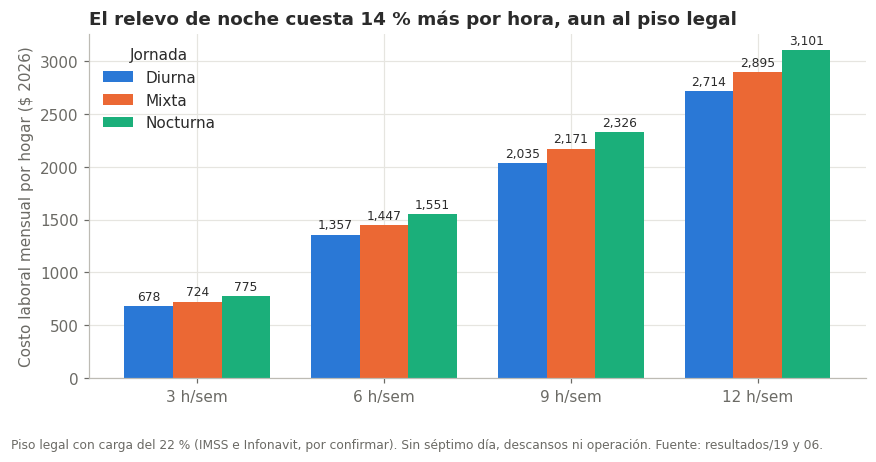

In [4]:
def costo(h, j, c): return SAL / DIV[JORN[j]] * h * SEM_MES * (1 + CARGA[c])

filas = [dict(Jornada=JORN[j], Horas=h, **{'Sin carga': costo(h, j, 1), 'Con 22 %': costo(h, j, 2), 'Carga ampliada': costo(h, j, 3)})
         for j in (1, 2, 3) for h in (3, 6, 9, 12)]
T_COSTO = pd.DataFrame(filas)
C_SEL = costo(BASE['horas'], BASE['jornada'], BASE['carga'])
assert abs(costo(6, 1, 1) - 1112) < 1, 'no coincide con el script 10 (diurna, 6 h, sin carga = $1,112)'
display(T_COSTO.style.format({'Sin carga': '{:,.0f}', 'Con 22 %': '{:,.0f}', 'Carga ampliada': '{:,.0f}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(8, 4.2))
horas = [3, 6, 9, 12]; ancho = 0.26
for k, j in enumerate((1, 2, 3)):
    vals = [costo(h, j, 2) for h in horas]
    b = ax.bar(np.arange(4) + (k - 1) * ancho, vals, ancho, color=eg.CAT[k], label=JORN[j])
    eg.etiquetas(ax, b, vals, fmt='{:,.0f}', dx=30, size=8)
ax.set_xticks(range(4)); ax.set_xticklabels([f'{h} h/sem' for h in horas])
ax.set_ylabel('Costo laboral mensual por hogar ($ 2026)'); ax.set_title('El relevo de noche cuesta 14 % más por hora, aun al piso legal')
ax.legend(title='Jornada', loc='upper left')
eg.nota(fig, 'Piso legal con carga del 22 % (IMSS e Infonavit, por confirmar). Sin séptimo día, descansos ni operación. Fuente: resultados/19 y 06.')
fig.savefig(FIG / 'f21_costo_relevo_por_jornada.png', dpi=150); plt.show()

## 4. Qué cubre el hogar y qué queda por financiar
Copago = lo menor entre el costo y el 20 % del ingreso del hogar. Subsidio laboral = costo − copago. Se calcula para tres hogares de referencia y para el promedio ponderado por el perfil del grupo del problema. Se muestran las dos fuentes de ingreso porque la decisión sigue pendiente, y mueven el resultado.

Costo laboral del paquete base: $1,357/mes · ingreso mínimo para pagarlo íntegro: $6,784


Fuente,Hogar,Ingreso 2026,Copago,Subsidio laboral
ENASIC nacional,Hogar p25,"4,618",924,433
ENASIC nacional,Hogar mediano,"7,851","1,357",0
ENASIC nacional,Hogar p75,"13,854","1,357",0
ENASIC nacional,Promedio ponderado,—,"1,186",171
ENIGH CDMX,Hogar p25,"11,303","1,357",0
ENIGH CDMX,Hogar mediano,"19,069","1,357",0
ENIGH CDMX,Hogar p75,"31,418","1,357",0
ENIGH CDMX,Promedio ponderado,—,"1,357",0


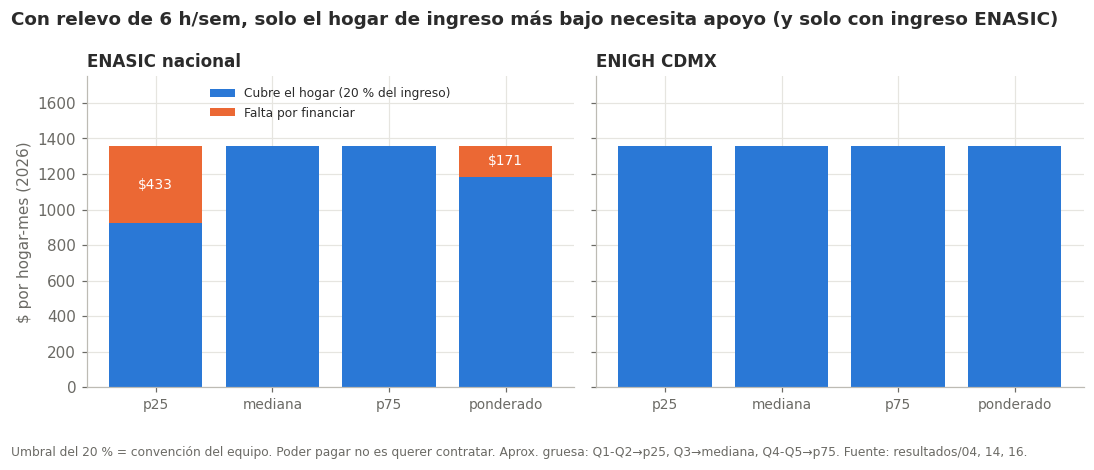

In [5]:
def copago_subsidio(cst, fuente, umbral=UMBRAL):
    cop = {k: min(cst, umbral * v) for k, v in ING[fuente].items()}
    sub = {k: cst - cop[k] for k in cop}
    return cop, sub, sum(W[k] * cop[k] for k in W), sum(W[k] * sub[k] for k in W)

filas = []
for f in (1, 2):
    cop, sub, cp, sp = copago_subsidio(C_SEL, f)
    for k, nom in (('p25', 'Hogar p25'), ('med', 'Hogar mediano'), ('p75', 'Hogar p75')):
        filas.append(dict(Fuente=FUENTE[f], Hogar=nom, **{'Ingreso 2026': ING[f][k], 'Copago': cop[k], 'Subsidio laboral': sub[k]}))
    filas.append(dict(Fuente=FUENTE[f], Hogar='Promedio ponderado', **{'Ingreso 2026': np.nan, 'Copago': cp, 'Subsidio laboral': sp}))
T_COP = pd.DataFrame(filas)
COP, SUB, COP_P, SUB_P = copago_subsidio(C_SEL, BASE['fuente'])
print(f'Costo laboral del paquete base: ${C_SEL:,.0f}/mes · ingreso mínimo para pagarlo íntegro: ${C_SEL / UMBRAL:,.0f}')
display(T_COP.style.format({'Ingreso 2026': '{:,.0f}', 'Copago': '{:,.0f}', 'Subsidio laboral': '{:,.0f}'}, na_rep='—').hide(axis='index'))

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, f in zip(axs, (1, 2)):
    sub_t = T_COP[T_COP.Fuente == FUENTE[f]]
    x = np.arange(len(sub_t))
    b1 = ax.bar(x, sub_t['Copago'], color=eg.AZUL, label='Cubre el hogar (20 % del ingreso)')
    b2 = ax.bar(x, sub_t['Subsidio laboral'], bottom=sub_t['Copago'], color=eg.NARANJA, label='Falta por financiar')
    for xi, cp_, sb_ in zip(x, sub_t['Copago'], sub_t['Subsidio laboral']):
        if sb_ > 1: ax.text(xi, cp_ + sb_ / 2, f'${sb_:,.0f}', ha='center', va='center', fontsize=9, color='white')
    ax.set_xticks(x); ax.set_xticklabels(['p25', 'mediana', 'p75', 'ponderado'], fontsize=9); ax.set_title(FUENTE[f], fontsize=11)
axs[0].set_ylabel('$ por hogar-mes (2026)'); axs[0].set_ylim(0, 1750); axs[0].legend(loc='upper center', fontsize=8, ncol=1)
fig.suptitle('Con relevo de 6 h/sem, solo el hogar de ingreso más bajo necesita apoyo (y solo con ingreso ENASIC)', x=0.01, ha='left', fontweight='bold', fontsize=12)
eg.nota(fig, 'Umbral del 20 % = convención del equipo. Poder pagar no es querer contratar. Aprox. gruesa: Q1-Q2→p25, Q3→mediana, Q4-Q5→p75. Fuente: resultados/04, 14, 16.')
fig.savefig(FIG / 'f22_copago_subsidio_relevo.png', dpi=150); plt.show()

## 5. Escala: CDMX (inferida) y piloto (ilustrativo)
Los elegibles de la CDMX salen de aplicar la razón nacional *grupo del problema / hogares con necesidad* a los hogares de la CDMX que mide la ENIGH. Es una inferencia de orden de magnitud: mezcla personas con hogares y usa tasas nacionales. La aceptación (qué fracción de los elegibles contrata) es **desconocida**: las filas baja y media son ilustrativas y la máxima es una cota (1 − "no contrataría a nadie"), no una predicción.

El financiamiento externo no es ingreso del programa: alguien tiene que ponerlo (gobierno, aliado o un pagador por costo evitado). Con una contratación actual de 1.0 % no hay volumen para financiar la operación con una comisión.

Razón grupo/hogares con necesidad: 5.01% → elegibles inferidos en la CDMX: 70,557 hogares (orden de magnitud)


Aceptación,Tasa,Hogares,Costo laboral anual (mdp),Subsidio laboral anual (mdp),% de la solicitud CDMX
Bajo (ilustrativo),5.0%,"3,528",57.4,7.2,0.11
Medio (ilustrativo),25.0%,"17,639",287.2,36.2,0.54
Máximo (cota),64.1%,"45,227",736.4,92.8,1.37



Financiamiento externo total anual (mdp) según el costo de operación por hogar-mes (ilustrativo):


,$0,$250,$500,"$1,000"
Bajo (ilustrativo),7.2,17.8,28.4,49.6
Medio (ilustrativo),36.2,89.1,142.0,247.9
Máximo (cota),92.8,228.5,364.1,635.5


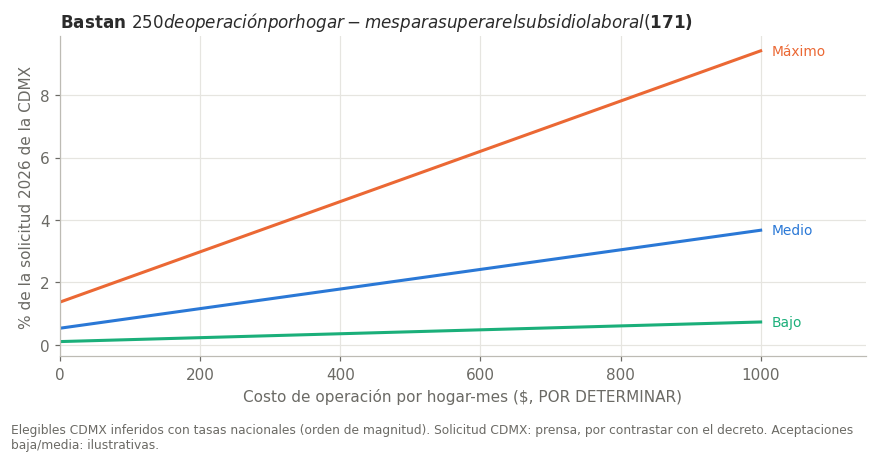


Piloto (tamaños ilustrativos: la sede no está definida):


Hogares,Costo laboral/mes ($),Copago/mes ($),Subsidio laboral/mes ($),"Financ. ext. anual (miles $), op. $0","Financ. ext. anual (miles $), op. $250","Financ. ext. anual (miles $), op. $500","Financ. ext. anual (miles $), op. $1000"
30,"40,705","35,572","5,128",62,152,242,422
60,"81,411","71,144","10,256",123,303,483,843
120,"162,822","142,287","20,513",246,606,966,"1,686"


In [6]:
RAZON = GRUPO_NAL / HOG_NAL
ELEG = HOG_CDMX * RAZON
TAKEUP = {'Bajo (ilustrativo)': TAKEUP_BAJO, 'Medio (ilustrativo)': TAKEUP_MEDIO, 'Máximo (cota)': 1 - NOCONT}
print(f'Razón grupo/hogares con necesidad: {RAZON:.2%} → elegibles inferidos en la CDMX: {ELEG:,.0f} hogares (orden de magnitud)')

T_ESC = pd.DataFrame([dict(Aceptación=nom, Tasa=t, Hogares=ELEG * t, **{'Costo laboral anual (mdp)': ELEG * t * C_SEL * 12 / 1e6,
                          'Subsidio laboral anual (mdp)': ELEG * t * SUB_P * 12 / 1e6, '% de la solicitud CDMX': 100 * ELEG * t * SUB_P * 12 / 1e6 / SOLIC})
                      for nom, t in TAKEUP.items()])
display(T_ESC.style.format({'Tasa': '{:.1%}', 'Hogares': '{:,.0f}', 'Costo laboral anual (mdp)': '{:,.1f}', 'Subsidio laboral anual (mdp)': '{:,.1f}', '% de la solicitud CDMX': '{:.2f}'}).hide(axis='index'))

# Financiamiento externo total = subsidio laboral + operación, en función del costo de operación por hogar-mes
T_FIN = pd.DataFrame({f'${o:,}': {nom: ELEG * t * (SUB_P + o) * 12 / 1e6 for nom, t in TAKEUP.items()} for o in OPEX_G})
print('\nFinanciamiento externo total anual (mdp) según el costo de operación por hogar-mes (ilustrativo):')
display(T_FIN.style.format('{:,.1f}'))

op = np.linspace(0, 1000, 101)
fig, ax = plt.subplots(figsize=(8, 4.2))
for (nom, t), col in zip(TAKEUP.items(), (eg.AQUA, eg.AZUL, eg.NARANJA)):
    y = 100 * ELEG * t * (SUB_P + op) * 12 / 1e6 / SOLIC
    ax.plot(op, y, color=col, lw=2); ax.text(op[-1] + 15, y[-1], nom.split(' ')[0], color=col, va='center', fontsize=9)
ax.set_xlim(0, 1150); ax.set_xlabel('Costo de operación por hogar-mes ($, POR DETERMINAR)'); ax.set_ylabel('% de la solicitud 2026 de la CDMX')
ax.set_title(f'Bastan $250 de operación por hogar-mes para superar el subsidio laboral (${SUB_P:,.0f})', fontsize=11)
eg.nota(fig, 'Elegibles CDMX inferidos con tasas nacionales (orden de magnitud). Solicitud CDMX: prensa, por contrastar con el decreto. Aceptaciones baja/media: ilustrativas.')
fig.savefig(FIG / 'f23_financiamiento_vs_operacion.png', dpi=150); plt.show()

T_PIL = pd.DataFrame([dict(Hogares=n, **{'Costo laboral/mes ($)': n * C_SEL, 'Copago/mes ($)': n * COP_P, 'Subsidio laboral/mes ($)': n * SUB_P},
                           **{f'Financ. ext. anual (miles $), op. ${o}': n * (SUB_P + o) * 12 / 1e3 for o in OPEX_G}) for n in PILOTO_N])
print('\nPiloto (tamaños ilustrativos: la sede no está definida):')
display(T_PIL.style.format('{:,.0f}').hide(axis='index'))

## 6. Escenario C: pagador por costo evitado
Una aseguradora, una empresa empleadora o un sistema de salud pagaría el relevo si evita un costo mayor. El indicador del piloto es si el relevo reduce la probabilidad de que la persona cuidadora deje su empleo o reduzca su jornada.

**Efecto mínimo exigido** = (costo laboral + operación) × 12 ÷ valor anual de una salida evitada, en puntos porcentuales. Se contrasta con la prevalencia declarada de daño al trabajo (cota superior de la salida del empleo, porque incluye "no puede trabajar fuera"): si el efecto exigido la supera, el esquema no puede cerrar. No hay evidencia propia de que 6 h/semana de relevo reduzcan la salida del empleo; el valor evitado es una rejilla ilustrativa. Lo que sí hace el cuadro es decirle al piloto **qué efecto tiene que encontrar**.

Operación por hogar-mes,$0,$250,$500,"$1,000"
Valor evitado por salida (anual),,,,
"$20,000",81.4 pp,96.4 pp,111.4 pp,141.4 pp
"$50,000",32.6 pp,38.6 pp,44.6 pp,56.6 pp
"$100,000",16.3 pp,19.3 pp,22.3 pp,28.3 pp
"$200,000",8.1 pp,9.6 pp,11.1 pp,14.1 pp


En rojo: efecto exigido > 47.7% (prevalencia declarada de daño al trabajo, IC90 39.3%–56.1%) → no puede cumplirse.


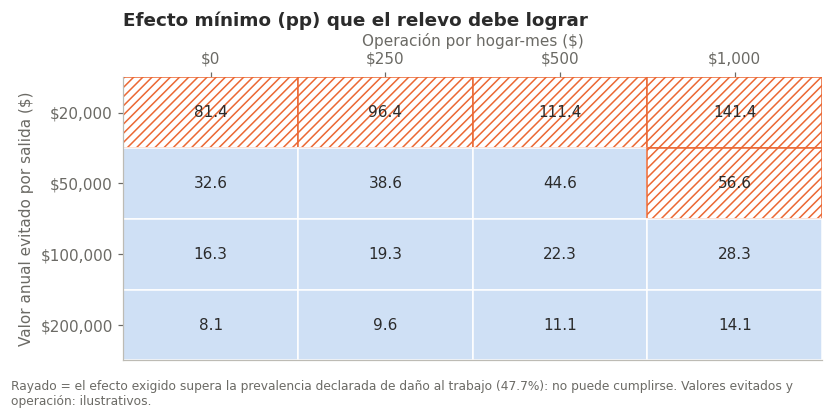

In [7]:
ef = pd.DataFrame({f'${o:,}': {f'${v:,}': 100 * (C_SEL + o) * 12 / v for v in VALOR_G} for o in OPEX_G})
ef.index.name = 'Valor evitado por salida (anual)'; ef.columns.name = 'Operación por hogar-mes'
_st = ef.style.format('{:.1f} pp')
_rojo = lambda x: 'color:#9c1c1c;font-weight:bold' if x > 100 * P0 else ''
display((_st.map if hasattr(_st, 'map') else _st.applymap)(_rojo))
print(f'En rojo: efecto exigido > {P0:.1%} (prevalencia declarada de daño al trabajo, IC90 {P0_LI:.1%}–{P0_LS:.1%}) → no puede cumplirse.')

fig, ax = plt.subplots(figsize=(7.6, 3.8))
M_ef = ef.values
for i in range(M_ef.shape[0]):
    for j in range(M_ef.shape[1]):
        imposible = M_ef[i, j] > 100 * P0
        ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor='white' if imposible else '#cfe0f5', edgecolor=eg.NARANJA if imposible else 'white',
                                   hatch='////' if imposible else None, lw=1))
        ax.text(j + .5, i + .5, f'{M_ef[i, j]:.1f}', ha='center', va='center', fontsize=10, color=eg.TINTA)
ax.set_xlim(0, 4); ax.set_ylim(4, 0); ax.set_xticks(np.arange(4) + .5); ax.set_xticklabels([f'${o:,}' for o in OPEX_G]); ax.set_yticks(np.arange(4) + .5)
ax.set_yticklabels([f'${v:,}' for v in VALOR_G]); ax.grid(False); ax.xaxis.tick_top(); ax.xaxis.set_label_position('top')
ax.set_xlabel('Operación por hogar-mes ($)'); ax.set_ylabel('Valor anual evitado por salida ($)')
ax.set_title('Efecto mínimo (pp) que el relevo debe lograr', pad=34)
eg.nota(fig, f'Rayado = el efecto exigido supera la prevalencia declarada de daño al trabajo ({P0:.1%}): no puede cumplirse. Valores evitados y operación: ilustrativos.')
fig.savefig(FIG / 'f24_escenario_c_efecto_minimo.png', dpi=150); plt.show()

## 7. ¿Qué supuesto mueve más el resultado?
Sensibilidad de un factor a la vez sobre el **subsidio laboral promedio por hogar-mes** (base: 6 h/sem, diurna, carga 22 %, ingreso ENASIC, umbral 20 %).

Caso,Subsidio,Cambio
"Carga ampliada (aguinaldo, vacaciones, prima)",207,+36
Jornada nocturna,247,+76
Sin carga laboral (control script 10),74,-97
Ingreso ENIGH CDMX en vez de ENASIC,0,-171
Relevo de 3 h/sem,0,-171
Umbral de asequibilidad 30 %,0,-171
Umbral de asequibilidad 10 % (en vez de 20 %),463,+292
Relevo de 12 h/sem,926,+755


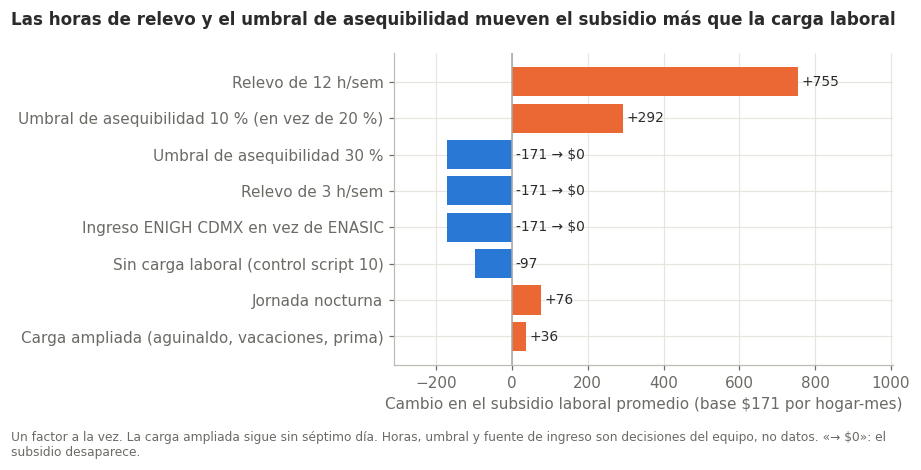

In [8]:
def subsidio_prom(h=6, j=1, c=2, f=1, umbral=UMBRAL): return copago_subsidio(costo(h, j, c), f, umbral)[3]
base = subsidio_prom()
casos = [('Ingreso ENIGH CDMX en vez de ENASIC', dict(f=2)), ('Umbral de asequibilidad 10 % (en vez de 20 %)', dict(umbral=.10)),
         ('Umbral de asequibilidad 30 %', dict(umbral=.30)), ('Sin carga laboral (control script 10)', dict(c=1)),
         ('Carga ampliada (aguinaldo, vacaciones, prima)', dict(c=3)), ('Jornada nocturna', dict(j=3)),
         ('Relevo de 3 h/sem', dict(h=3)), ('Relevo de 12 h/sem', dict(h=12))]
T_TOR = pd.DataFrame([dict(Caso=n, Subsidio=subsidio_prom(**k), Cambio=subsidio_prom(**k) - base) for n, k in casos]).sort_values('Cambio', key=abs)
display(T_TOR.style.format({'Subsidio': '{:,.0f}', 'Cambio': '{:+,.0f}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(8.4, 4.2))
cols = [eg.NARANJA if v > 0 else eg.AZUL for v in T_TOR['Cambio']]
b = ax.barh(T_TOR['Caso'], T_TOR['Cambio'], color=cols)
for bar, v in zip(b, T_TOR['Cambio']):
    ax.text((v if v >= 0 else 0) + 10, bar.get_y() + bar.get_height() / 2, f'{v:+,.0f}' + (' → $0' if abs(v + base) < 0.5 else ''), va='center', ha='left', fontsize=9)
ax.axvline(0, color=eg.GRIS, lw=1); ax.set_xlabel(f'Cambio en el subsidio laboral promedio (base ${base:,.0f} por hogar-mes)')
fig.suptitle('Las horas de relevo y el umbral de asequibilidad mueven el subsidio más que la carga laboral', x=0.01, ha='left', fontweight='bold', fontsize=11)
ax.set_xlim(T_TOR['Cambio'].min() - 140, T_TOR['Cambio'].max() + 250)
fig.subplots_adjust(top=0.9)
eg.nota(fig, 'Un factor a la vez. La carga ampliada sigue sin séptimo día. Horas, umbral y fuente de ingreso son decisiones del equipo, no datos. «→ $0»: el subsidio desaparece.')
fig.savefig(FIG / 'f25_sensibilidad_subsidio.png', dpi=150); plt.show()

## 8. Control contra el libro de Excel
`20_modelo_sostenibilidad.py` genera el libro con fórmulas vivas y un CSV con los mismos cálculos hechos en Python. Esta celda recalcula todo en el notebook y exige que coincidan. Si alguien cambia un supuesto en un lugar y no en el otro, aquí se rompe.

In [9]:
ctl = pd.read_csv(RES / '20_sostenibilidad_escenarios.csv', encoding='utf-8-sig')
errores = []
def chk(nombre, a, b, tol=0.011):
    if abs(a - b) > tol: errores.append((nombre, a, b))

for _, r in ctl[ctl.bloque == 'costo_unitario'].iterrows():
    j = [k for k, v in JORN.items() if v == r.jornada][0]
    chk(f'costo {r.jornada} {r.horas_semana} h c{int(r.carga)}', costo(int(r.horas_semana), j, int(r.carga)), r.costo_mensual)
c_sel_csv = None
for _, r in ctl[(ctl.bloque == 'copago') & (ctl.hogar != 'ponderado')].iterrows():
    f = 1 if r.fuente_ingreso == 'ENASIC nacional' else 2
    k = r.hogar; cop, sub, _, _ = copago_subsidio(C_SEL, f)
    chk(f'copago {r.fuente_ingreso} {k}', cop[k], r.copago); chk(f'subsidio {r.fuente_ingreso} {k}', sub[k], r.subsidio_laboral)
for _, r in ctl[ctl.bloque == 'escala_cdmx'].iterrows():
    t = list(TAKEUP.values())[list(ctl[ctl.bloque == 'escala_cdmx'].index).index(_)]
    chk('hogares', ELEG * t, r.hogares, 0.51); chk('subsidio anual mdp', ELEG * t * SUB_P * 12 / 1e6, r.subsidio_laboral_anual_mdp)
for _, r in ctl[ctl.bloque == 'financiamiento_total_cdmx'].iterrows():
    t = [v for k, v in TAKEUP.items() if k.split(' ')[0].lower() == r.escenario.split(' ')[0]][0]
    chk('financiamiento', ELEG * t * (SUB_P + r.opex_hogar_mes) * 12 / 1e6, r.mdp)
for _, r in ctl[ctl.bloque == 'costo_evitado'].iterrows():
    chk('efecto mínimo', 100 * (C_SEL + r.opex_hogar_mes) * 12 / r.valor_evento_anual, r.efecto_minimo_pp)
assert not errores, errores
print(f'OK: {len(ctl)} filas del CSV del script 20 reproducidas en el notebook (tolerancia de redondeo).')

OK: 75 filas del CSV del script 20 reproducidas en el notebook (tolerancia de redondeo).


In [10]:
display(Markdown(f"""## 9. Lectura con los parámetros base
*(Texto generado con las cifras de las celdas anteriores; cambia si cambian los supuestos.)*

1. **Costo.** Con relevo de 6 h/semana, diurno y carga del 22 %, el costo laboral es **${C_SEL:,.0f} al mes** por hogar. Bajo el umbral del 20 %, lo paga íntegro un hogar con ingreso de ${C_SEL / UMBRAL:,.0f} o más: el hogar mediano de la ENASIC (${ING[1]['med']:,.0f}) sí; el del p25 (${ING[1]['p25']:,.0f}) cubre ${COP['p25']:,.0f}.
2. **Esto corrige el estudio de negocio v0.2.** El subsidio "inviable" era el de 20 y 40 h. En relevo de 6 h el subsidio laboral promedio es de **${SUB_P:,.0f} por hogar-mes** con ingreso ENASIC y de ${copago_subsidio(C_SEL, 2)[3]:,.0f} con ingreso ENIGH CDMX. Bajo la convención del 20 %, el precio del relevo deja de ser la barrera principal de financiamiento; **eso no implica que los hogares lo contraten**.
3. **Lo que decide la sostenibilidad.** La operación (POR DETERMINAR) y la aceptación. Hoy contrata {CONTRATA_HOY:.1%} de los hogares con necesidad y {NOCONT:.1%} de las cuidadoras de personas con discapacidad o de 60+ no contrataría a nadie: asequible no es aceptado. Eso lo mide el piloto (H1 contra H2).
4. **Escala (inferida).** ≈{ELEG:,.0f} hogares elegibles en la CDMX. Con aceptación media ({TAKEUP_MEDIO:.0%}, ilustrativa) el subsidio laboral sería de {ELEG * TAKEUP_MEDIO * SUB_P * 12 / 1e6:,.1f} mdp al año ({100 * ELEG * TAKEUP_MEDIO * SUB_P * 12 / 1e6 / SOLIC:.1f} % de la solicitud de la CDMX); con la cota máxima, {ELEG * (1 - NOCONT) * SUB_P * 12 / 1e6:,.1f} mdp ({100 * ELEG * (1 - NOCONT) * SUB_P * 12 / 1e6 / SOLIC:.1f} %).
5. **Lo que más mueve el resultado** son decisiones de diseño, no datos: cuántas horas de relevo se ofrecen (12 h multiplican el subsidio por varias veces; 3 h lo eliminan), el umbral de asequibilidad y la fuente del ingreso. La carga laboral y el horario nocturno mueven menos. La ENASIC capta cerca de la mitad del ingreso que mide la ENIGH, así que con la ENASIC el subsidio sale sobreestimado.
6. **Escenario C.** Con un valor evitado de $100,000 al año por salida, el relevo tendría que reducir la probabilidad de salida en {100 * C_SEL * 12 / 100000:.1f} pp solo por su costo laboral. Con $20,000 el efecto exigido ({100 * C_SEL * 12 / 20000:.0f} pp) supera la prevalencia declarada de daño al trabajo ({P0:.1%}): no puede cumplirse.

## 10. Límites y pendientes
- **No hay punto de equilibrio**: faltan la operación (coordinación, verificación y formación, plataforma, nómina) y la aceptación. El libro de Excel tiene la celda `opex_real` para llenarla cuando exista.
- **Costo laboral subestimado**: sin séptimo día ni descansos de jornadas por horas; carga del 22 % por confirmar con el IMSS; arts. 60, 61, 76, 80 y 87 de la LFT por verificar en el DOF (Daniel).
- **Asequibilidad no es disposición a pagar.** El 20 % es una convención del equipo.
- **CDMX es una inferencia**, y la solicitud 2026 viene de prensa (contrastar con el decreto).
- **El modelo cuenta hogares, no personas**: la beneficiaria final es quien recibe el cuidado.
- **Sin evidencia propia** de que el relevo reduzca el daño o la salida del empleo.
- **Pendiente de doble revisión** por alguien distinto a quien lo produjo.
"""))

## 9. Lectura con los parámetros base
*(Texto generado con las cifras de las celdas anteriores; cambia si cambian los supuestos.)*

1. **Costo.** Con relevo de 6 h/semana, diurno y carga del 22 %, el costo laboral es **$1,357 al mes** por hogar. Bajo el umbral del 20 %, lo paga íntegro un hogar con ingreso de $6,784 o más: el hogar mediano de la ENASIC ($7,851) sí; el del p25 ($4,618) cubre $924.
2. **Esto corrige el estudio de negocio v0.2.** El subsidio "inviable" era el de 20 y 40 h. En relevo de 6 h el subsidio laboral promedio es de **$171 por hogar-mes** con ingreso ENASIC y de $0 con ingreso ENIGH CDMX. Bajo la convención del 20 %, el precio del relevo deja de ser la barrera principal de financiamiento; **eso no implica que los hogares lo contraten**.
3. **Lo que decide la sostenibilidad.** La operación (POR DETERMINAR) y la aceptación. Hoy contrata 1.0% de los hogares con necesidad y 35.9% de las cuidadoras de personas con discapacidad o de 60+ no contrataría a nadie: asequible no es aceptado. Eso lo mide el piloto (H1 contra H2).
4. **Escala (inferida).** ≈70,557 hogares elegibles en la CDMX. Con aceptación media (25%, ilustrativa) el subsidio laboral sería de 36.2 mdp al año (0.5 % de la solicitud de la CDMX); con la cota máxima, 92.8 mdp (1.4 %).
5. **Lo que más mueve el resultado** son decisiones de diseño, no datos: cuántas horas de relevo se ofrecen (12 h multiplican el subsidio por varias veces; 3 h lo eliminan), el umbral de asequibilidad y la fuente del ingreso. La carga laboral y el horario nocturno mueven menos. La ENASIC capta cerca de la mitad del ingreso que mide la ENIGH, así que con la ENASIC el subsidio sale sobreestimado.
6. **Escenario C.** Con un valor evitado de $100,000 al año por salida, el relevo tendría que reducir la probabilidad de salida en 16.3 pp solo por su costo laboral. Con $20,000 el efecto exigido (81 pp) supera la prevalencia declarada de daño al trabajo (47.7%): no puede cumplirse.

## 10. Límites y pendientes
- **No hay punto de equilibrio**: faltan la operación (coordinación, verificación y formación, plataforma, nómina) y la aceptación. El libro de Excel tiene la celda `opex_real` para llenarla cuando exista.
- **Costo laboral subestimado**: sin séptimo día ni descansos de jornadas por horas; carga del 22 % por confirmar con el IMSS; arts. 60, 61, 76, 80 y 87 de la LFT por verificar en el DOF (Daniel).
- **Asequibilidad no es disposición a pagar.** El 20 % es una convención del equipo.
- **CDMX es una inferencia**, y la solicitud 2026 viene de prensa (contrastar con el decreto).
- **El modelo cuenta hogares, no personas**: la beneficiaria final es quien recibe el cuidado.
- **Sin evidencia propia** de que el relevo reduzca el daño o la salida del empleo.
- **Pendiente de doble revisión** por alguien distinto a quien lo produjo.
